**수행평가 제출용 — 보행 영역 분할과 방향 후보**

학번: [본인 입력]　이름: [본인 입력]

**읽는 방법:** 아래 저장된 표·그래프·비교 이미지를 위에서부터 확인하세요. 결과 확인에는 GPU·Drive 연결·전체 실행이 필요 없습니다. 실행 플래그는 모두 꺼져 있습니다. 코드 셀의 저장된 결과는 완료한 실험 기록이며 새 학습 결과가 아닙니다.

**구성:** ① 기존 모델 탐색과 환경 ② 데이터·정답·검수 ③ B0/B2 학습 ④ 고정 테스트·방향 후보·해석.

| 항목 | 실제 수행 내용 |
|---|---|
| 예측할 것 | 이미지 각 픽셀이 차도·인도·자전거도로 중 어디에 속하는지 |
| 입력 X / 정답 y | RGB 이미지 / 픽셀별 검수된 ID 마스크 |
| 데이터 | AI Hub 인도보행 영상 Surface_1.zip에서 350장 추출·검수 |
| 분할 | 학습 251장 / 검증 39장 / 고정 테스트 60장 |
| 학습 | SegFormer B0(A), B2(C), 같은 검수 라벨 사용 |
| 테스트 mIoU | B0 57.74% / B2 62.66% |
| 추가 구현 | B2 인도 예측에서 연결된 보행 방향 후보 계산 |
| 방향 처리 시간 | T4·FP32, 평균 208.3 ms/장 |
| 미측정 항목 | 사람 방향 정답이 없어 방향 정확도 미측정 |

# 1. 기존 5개 모델 분할 코드

기존 시스템의 보행 영역 판정 개선을 위해 분할 모델을 탐색했다. 초기 5개 모델은 사진 4장씩 총 20건의 탐색 추론을 수행했다. 정답 마스크가 없는 탐색 사진의 결과는 정량 순위로 사용하지 않았다. 최종 학습 비교는 아래 B0/B2 두 모델이다.

In [ ]:
# 선택 실행: 재현을 원할 때만 True. 결과 열람에는 실행할 필요 없음.
RUN_REPRODUCTION = False
import sys, subprocess, json
from pathlib import Path
REPO_URL = 'https://github.com/i3l3/sidewalk-segmentation-benchmark.git'
REPO_DIR = Path('/content/sidewalk-segmentation-benchmark')
ROOT = Path('/content/drive/MyDrive/Sidewalk-Segmentation-Benchmark')
if RUN_REPRODUCTION:
    if not REPO_DIR.exists():
        subprocess.run(['git','clone',REPO_URL,str(REPO_DIR)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-r',str(REPO_DIR/'requirements.txt')],check=True)
    from google.colab import drive
    drive.mount('/content/drive')
    sys.path.insert(0,str(REPO_DIR))
def run(command,*args):
    if not RUN_REPRODUCTION:
        raise RuntimeError('재현 설정을 먼저 실행하세요.')
    subprocess.run([sys.executable,'-m','src.runner',command,'--root',str(ROOT),*map(str,args)],cwd=REPO_DIR,check=True)
print('결과 열람 모드입니다. 학습·다운로드는 자동으로 실행하지 않습니다.')


결과 열람 모드입니다. 학습·다운로드는 자동으로 실행하지 않습니다.


| 초기 모델 | 용도 |
|---|---|
| Mask2Former Swin-L | 탐색 분할 |
| OneFormer DiNAT-L | 탐색 분할 |
| Mask2Former R50 | 탐색 분할 |
| SegFormer B5 | 탐색 분할 |
| SegFormer B2 | 탐색 분할 |

기존 로더·시각화는 `legacy/`에 유지했다. 원본 구현의 의존성 충돌을 줄이기 위해 모델 실행은 독립 프로세스로 분리한다. 탐색 사진 4장과 예측 20개는 학습·검증·최종 테스트에 넣지 않았다. 다운로드·Tailscale 설정 같은 개발 과정은 재현용 노트북에 보존하고 채점용 본문에서는 생략했다.

In [ ]:
RUN_LEGACY_EXPLORATION = False
if RUN_LEGACY_EXPLORATION:
    for model in ['mask2former_swin_l','oneformer_dinat_l','mask2former_r50','segformer_b5','segformer_b2']:
        # 기존 탐색 자료는 별도 root에 두어 학습 데이터와 분리
        subprocess.run([sys.executable,'-m','src.runner','benchmark','--root',str(ROOT/'exploration'),'--models',model],cwd=REPO_DIR,check=True)


# 2. 데이터셋 라벨링 코드

**출처:** [AI Hub 인도보행 영상](https://www.aihub.or.kr/aihubdata/data/view.do?aihubDataSe=data&currMenu=1&dataSetSn=189&topMenu=). `Surface_1.zip`에서 이미지 350장과 공식 XML 정답을 사용했다. 자동 Teacher 초안을 정답으로 간주한 실험이 아니며, 공식 주석을 현재 클래스에 맞춰 변환하고 사용자 검수를 거쳤다.

| 속성·파일 | 내용과 의미 | 형태·범위 |
|---|---|---|
| image | 원본 RGB 영상의 한 프레임 | JPG, 1920×1080, 채널 3개, 0~255 |
| mask | 이미지와 같은 위치의 정답 클래스 | 단일 채널 PNG, 저장 ID 1·2·8·255 |
| image_id / image_path | 표본 식별자 / 이미지 상대 경로 | 문자열 |
| group_id / split | 촬영일 기반 그룹 / 학습·검증·테스트 구분 | 범주형 |
| status / label_verified | 라벨 검수 상태 / 확인 여부 | reviewed / true |
| image_sha / mask_sha | 검수한 파일이 이후 바뀌었는지 확인 | SHA-256 문자열 |

이미지와 정답 마스크가 학습 데이터이고, CSV는 파일 경로·분할·검수 기록을 관리하는 목록이다.
색상은 표시용이며 실제 손실 계산은 정수 클래스 ID로 한다.

| 클래스 | 의미 | 저장 ID → 학습 헤드 ID |
|---|---|---|
| 차도 | 일반 차도와 골목의 normal/speed_bump/damaged 영역 | 1 → 0 |
| 인도 | sidewalk로 주석된 영역 | 2 → 1 |
| 자전거도로 | bike_lane로 주석된 영역 | 8 → 2 |
| 학습·평가 제외 | 미표기, 점자블록, 주의/공사 구역, 횡단보도 속성 등 | 255 → 255 |

미표기를 ‘기타’ 정답으로 취급하지 않는다. 기존 9종 저장 체계를 유지하되 현재 모델의 출력 헤드는 3개다.

## 전처리·검수·분할을 한 이유

1. ZIP 전체를 해제하지 않고 XML 폴리곤이 지원되는 이미지에서 seed 42로 폴더별 분산 표본 350장을 준비했다. 원본 RGB 마스크의 색을 추측하지 않고 XML 폴리곤과 겹침 순서로 ID 마스크를 만들었다.
2. 육안 검수 피드백에서 골목의 차도 누락을 확인하여 사용자 확인 후 차도 정의에 골목을 포함했다. 350장의 라벨 검수 확인을 기록하고 파일 해시로 상태를 추적했다.
3. 이미지·마스크 크기, 허용 ID, 누락 파일, 전부 ignore인 표본과 중복을 검사한다. 라벨이 없는 픽셀은 추정해 채우지 않고 255로 제외한다.
4. 촬영일 식별자별로 묶고 dHash 거리 4 이하의 유사 사진 그룹을 합쳤다. 그룹을 나누지 않아 목표 250/50/50 대신 251/39/60이 됐다. 분할 간 동일 파일·dHash≤4 유사 쌍·그룹 중복은 각각 0건이었다. 실제 장소 독립성은 확인되지 않았다.
5. 학습 입력은 512×512로 변환하고 RGB를 ImageNet 평균·표준편차로 정규화한다. 이미지와 정답에 같은 기하 증강을 적용한다. 정답 리사이즈에는 nearest-neighbor만 사용하여 새 클래스 값이 생기지 않게 한다.
6. 수치형 표 데이터처럼 임의의 행·열을 삭제하거나 평균으로 결측치를 채우지 않는다. 모래로 덮인 인도 같은 어려운 장면도 실패 사례로 다루며, 테스트 결과가 나쁘다는 이유로 제거하지 않았다.

In [ ]:
# 재현 옵션: 기존 제출 데이터는 다시 만들지 않음. 새 경로에 별도 준비할 때만 사용.
RUN_NEW_DATA_PREPARATION = False
NEW_DATA_ROOT = Path('/content/sidewalk_new_data_version')
if RUN_NEW_DATA_PREPARATION:
    if not RUN_REPRODUCTION:raise RuntimeError('재현 설정을 먼저 실행하세요.')
    from src.surface_import import prepare_surface
    from src.schema import configure_task
    configure_task(NEW_DATA_ROOT,[1,2,8])
    prepare_surface(NEW_DATA_ROOT,ROOT/'data/downloads/aihub_189/manual/Surface_1.zip',count=350,seed=42)
    print('새 데이터의 육안 검수와 그룹 확인은 별도로 해야 합니다. 자동 승인하지 않습니다.')


## 최종 데이터 점검 기록

| 구분 | 학습 | 검증 | 테스트 |
|---|---:|---:|---:|
| 전체 이미지 | 251 | 39 | 60 |
| 차도 포함 | 195 | 32 | 36 |
| 인도 포함 | 248 | 39 | 60 |
| 자전거도로 포함 | 19 | 3 | 7 |

350장 검수 완료. 파일 해시가 바뀌면 검수 상태를 해제한다. 파일·유사 사진·프록시 그룹의 분할 간 중복 검사는 0건이다. 촬영일 기준은 실제 장소의 완전한 독립을 보장하지 않는다. 분할 목록과 테스트 목록은 Drive `data/splits/`에 고정했다.

# 3. 모델 학습 또는 파인튜닝 코드

**실행 완료: A=B0, C=B2, 둘 다 같은 검수 라벨만 사용.**

입력 X는 정규화 RGB 텐서, 정답 y는 대응하는 픽셀 클래스다. ImageNet 사전학습 인코더에 새 3종 분할 헤드를 붙였다. B0/B2는 모델 규모가 달라 같은 조건에서 성능과 자원 사용을 비교했다. 초기 새 헤드를 과거 학습 완료 모델로 취급하지 않는다.

| 설정 | 실제 값 |
|---|---|
| seed / 입력 | 42 / 512×512 |
| optimizer / lr / weight decay | AdamW / 6e-5 / 0.01 |
| 손실 | Cross-Entropy, ignore=255 제외 |
| 유효 배치 / microbatch / 누적 | 8 / 2 / 4 |
| 최대 epoch / early stopping | 20 / 검증 mIoU patience 5 |
| GPU / 학습 정밀도 | Tesla T4 / FP16 AMP |
| 선택 기준 | 검증 mIoU가 가장 높은 Best 체크포인트 |

B0는 20epoch 중 19epoch를, B2는 조기 종료한 14epoch 중 9epoch를 Best로 선택했다. 테스트 점수로 학습 설정을 조정하지 않았다. 모델·optimizer·scheduler·AMP·난수·epoch를 저장하여 중단 후 재개할 수 있다. 별도 합성 자료로 저장→재개 흐름을 검증했고 합성 성능을 실제 성능에 섞지 않았다.

In [ ]:
RUN_TRAIN_A_C = False  # 이미 완료했으므로 결과 확인 시 False 유지
TRAIN_CONFIG = {'seed':42,'size':512,'epochs':20,'lr':6e-5,'weight_decay':0.01,
                'effective_batch':8,'microbatch':2,'patience':5}
if RUN_TRAIN_A_C:
    for experiment in ['A','C']:
        run('train','--experiment',experiment,'--config',json.dumps(TRAIN_CONFIG))


핵심 학습 구현은 `src/training.py`의 `SegmentationDataset`, `safe_loss`, `train`이다. 검수 라벨·검증 세트가 없으면 정식 학습을 거부한다. 전체 파일은 함께 제공한 `코드_전체.md`와 `source.zip`에서 볼 수 있다. B/D와 9종 확장은 기능만 보존했으며 이번 실험 결과로 제시하지 않는다.

# 4. 성능 검증 코드

검증 세트로 선택한 Best 체크포인트를 같은 고정 테스트 60장에서 평가했다. 정답 ignore=255를 제외한 누적 confusion matrix로 IoU·Precision·Recall·Pixel Accuracy를 구했다.

**IoU** = TP/(TP+FP+FN), **mIoU** = 3개 클래스 IoU의 평균. 클래스 불균형 때문에 Pixel Accuracy만으로 모델을 판단하지 않는다.

In [ ]:
RUN_FIXED_TEST_EVALUATION = False
if RUN_FIXED_TEST_EVALUATION:
    for experiment in ['A','C']:
        run('evaluate','--experiment',experiment,'--split','test')


## 실제 테스트 결과

| 모델 | 완료 epoch | Best epoch | 검증 mIoU | 테스트 mIoU | 테스트 Pixel Accuracy |
|---|---:|---:|---:|---:|---:|
| B0 | 20 | 19 | 73.70% | 57.74% | 88.42% |
| B2 | 14 | 9 | 82.30% | 62.66% | 89.42% |

| 모델 | 차도 IoU | 인도 IoU | 자전거도로 IoU |
|---|---:|---:|---:|
| B0 | 58.85% | 87.16% | 27.19% |
| B2 | 73.26% | 87.83% | 26.89% |

B2는 같은 고정 테스트에서 B0보다 mIoU가 **4.93%p** 높았다. 차도 IoU는 **14.41%p**, 인도 IoU는 **0.67%p** 높았지만 자전거도로 IoU는 **0.30%p 낮았다**. 모든 클래스가 개선됐다고 해석하지 않는다.

설계상 모델 규모가 큰 B2의 표현력이 유리할 수 있다고 기대할 수 있으나 사전에 기록한 수치 목표는 없다. 실제로 전체 mIoU는 높았지만 자전거도로에는 이점이 나타나지 않았다.

이는 두 구조를 같은 자료로 학습한 비교이며, 동일 모델의 학습 전후 개선율이 아니다. 학습 전의 새 헤드는 무작위 초기화 상태였고 별도 성능 기준으로 측정하지 않았다.

검증 점수는 512×512, 테스트 점수는 원본 크기로 복원한 예측에서 계산했다. 검증-테스트 차이에는 분할 장면 차이·과적합 가능성·평가 해상도 차이가 함께 작용할 수 있어 원인을 하나로 단정할 수 없다.

자전거도로가 포함된 사진은 학습 19장·검증 3장·테스트 7장으로 적다. 인도 픽셀이 많아 Pixel Accuracy만 보면 자전거도로의 낮은 성능이 가려지므로 클래스별 IoU와 mIoU를 함께 본다. Boundary F1은 원본 해상도·허용 오차 2px 조건에서 B0 0.0096, B2 0.0247로 낮아 경계 품질도 추가 개선이 필요하다.

In [ ]:
# 실측 JSON 스냅샷을 다시 표시한다. 새 학습·추론을 수행하는 셀이 아님.
RESULTS = json.loads('{"provenance": "completed A/C experiment records; redisplay only", "experiments": [{"experiment": "A", "model": "B0", "epochs_completed": 20, "best_epoch": 19, "best_validation_miou": 0.7370055923834231, "test_miou": 0.5773580287955415, "test_pixel_accuracy": 0.8841801741990969, "test_images": 60, "mean_boundary_f1": 0.009626517795547703, "mean_inference_seconds": 0.027200240916666445, "max_inference_gpu_mib": 190.392578125, "max_training_gpu_mib": 822.6650390625, "training_epoch_seconds": 857.7118366599999, "model_parameters": 3714915, "best_weights_sha256": "29b895bf16c2721302ff46dabd66507c897a82bfdd8fc6a67e9a768a7ce1723f", "best_checkpoint": "/content/drive/MyDrive/Sidewalk-Segmentation-Benchmark/checkpoints/A/best", "source_pretrained_model": "nvidia/mit-b0", "pretrained_revision": "80983a413c30d36a39c20203974ae7807835e2b4"}, {"experiment": "C", "model": "B2", "epochs_completed": 14, "best_epoch": 9, "best_validation_miou": 0.8229860317693495, "test_miou": 0.6266251500807655, "test_pixel_accuracy": 0.8941906706821633, "test_images": 60, "mean_boundary_f1": 0.0247343914482625, "mean_inference_seconds": 0.08712008418335697, "max_inference_gpu_mib": 574.1513671875, "max_training_gpu_mib": 2578.82421875, "training_epoch_seconds": 843.1959401550002, "model_parameters": 27348931, "best_weights_sha256": "2422e38a0a893d862bb5f3acfaac5800db19fe0c829569cff169a900dfbdd248", "best_checkpoint": "/content/drive/MyDrive/Sidewalk-Segmentation-Benchmark/checkpoints/C/best", "source_pretrained_model": "nvidia/mit-b2", "pretrained_revision": "3bb39e8739149c3777d0325349b2a6c32c6413db"}], "direction_timing": {"images": 60, "split": "test", "device": "cuda", "hardware": "Tesla T4", "torch": "2.11.0+cu130", "precision": "FP32", "batch_size": 1, "input_size": 512, "warmup_images": 1, "model_load_seconds": 0.4852271319996362, "timing_scope": "RGB image in memory through resize, model, original-resolution mask and route; excludes disk IO, model loading and rendering", "latency_seconds": {"preprocess": {"mean": 0.019618878583317685, "median": 0.018960375000006024, "p95": 0.023752991499986807}, "inference_and_mask": {"mean": 0.10028984463336504, "median": 0.0994205895003688, "p95": 0.10507938029973046}, "route": {"mean": 0.08843893373336868, "median": 0.09200579050002489, "p95": 0.11466150284963987}, "pipeline": {"mean": 0.20834765695005142, "median": 0.2127145604999896, "p95": 0.23385803259989188}}, "candidate_counts": {"Left": 44, "Right": 7, "Straight": 4, "No clear path": 5}, "no_clear_path_fraction": 0.08333333333333333, "paths_verified_inside_prediction": 55, "paths_checked": 55, "minimum_cached_mask_agreement": 1.0, "peak_cuda_allocated_mib": 557.9638671875, "direction_accuracy": null, "thresholds_tuned_on_test": false, "checkpoint_sha256": "2422e38a0a893d862bb5f3acfaac5800db19fe0c829569cff169a900dfbdd248"}}')
for record in RESULTS['experiments']:
    print(f"{record['model']}: test mIoU={record['test_miou']:.6f}, Pixel Accuracy={record['test_pixel_accuracy']:.6f}")


B0: test mIoU=0.577358, Pixel Accuracy=0.884180
B2: test mIoU=0.626625, Pixel Accuracy=0.894191


## 학습 곡선과 클래스별 성능

실제 학습·검증 기록과 고정 테스트 지표를 시각화했다.

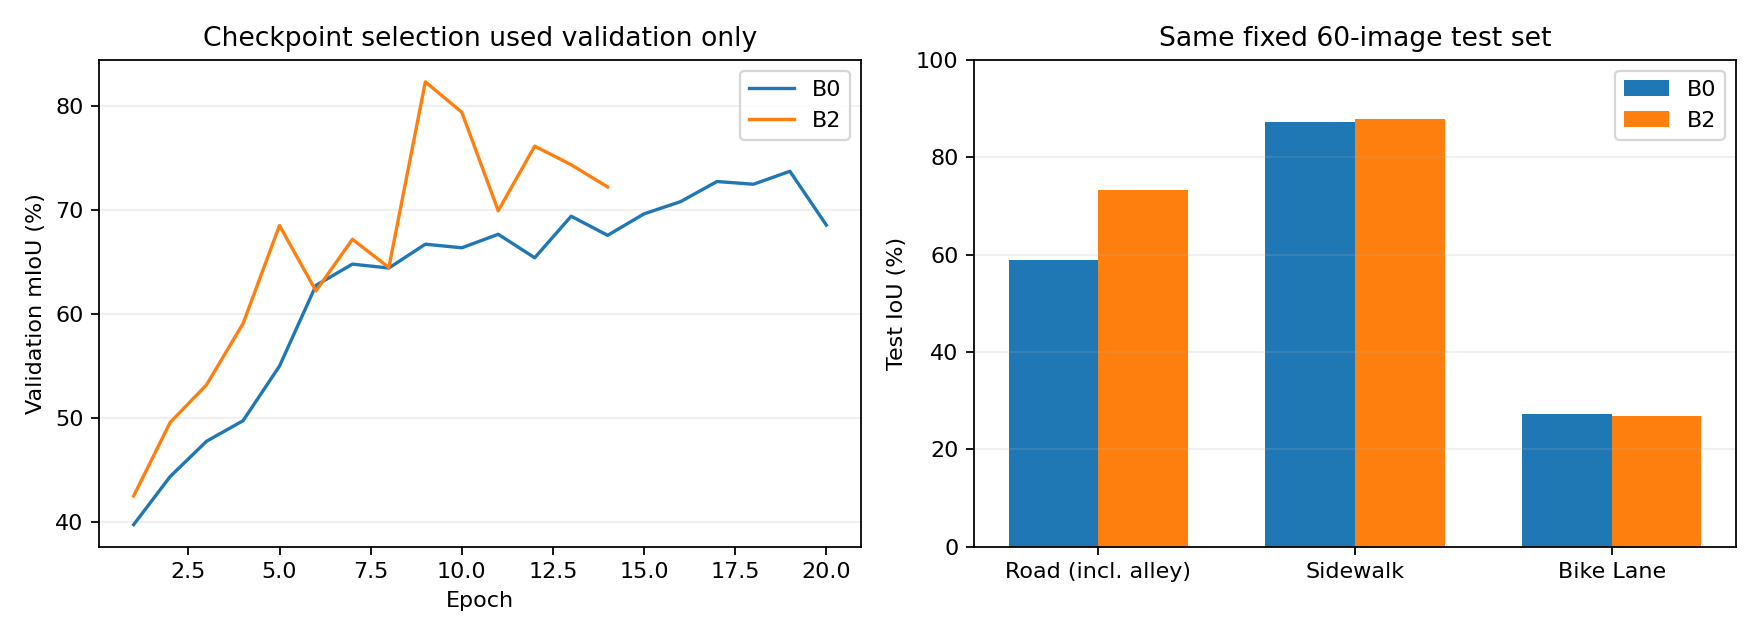

In [ ]:
from IPython.display import display, Image, Markdown
_name = 'B0_B2_comparison.png'
_candidates = [Path(_name), ROOT/'reports'/_name, ROOT/'reports/graphs'/_name]
_file = next((p for p in _candidates if p.exists()), None)
if _file:display(Image(filename=str(_file)))
else:display(Markdown('저장된 그림은 제출용 사본에서 확인하세요. 재실행에는 결과 파일 경로가 필요합니다.'))


## 원본·정답·예측·오류·연석 확대 비교

고정 테스트 목록의 처음 6장이다. 결과가 좋아 보이는 사진을 골라 넣지 않았다. ignore 영역은 어둡게 표시한다. 연석은 현재 독립 학습 클래스가 아니므로 확대 이미지는 주변 경계 관찰용이다.

In [ ]:
from IPython.display import display, Image, Markdown
_name = 'B0_B2_test_examples.jpg'
_candidates = [Path(_name), ROOT/'reports'/_name, ROOT/'reports/graphs'/_name]
_file = next((p for p in _candidates if p.exists()), None)
if _file:display(Image(filename=str(_file)))
else:display(Markdown('저장된 그림은 제출용 사본에서 확인하세요. 재실행에는 결과 파일 경로가 필요합니다.'))


## B2 보행 방향 후보와 처리 시간

화면 하단 60%에서 인도만 후보로 사용하고, 하단 5%·중앙 20%와 연결된 성분을 찾는다. 차도·자전거도로는 후보에서 제외한다. 연결성, 영상 대비 폭, 중심 편차를 계산하고 격자에서 연결된 경로를 탐색한다. 원본 해상도에서도 경로 중심선이 예측 인도 밖으로 나가지 않는지 확인한다. 연결이 없거나 조건을 만족하지 못하면 `No clear path`(판단 보류)를 낸다.

| 방향 후보 | 왼쪽 | 직진 | 오른쪽 | 판단 보류 |
|---|---:|---:|---:|---:|
| 고정 테스트 60장 | 44 | 4 | 7 | 5 (8.3%) |

Tesla T4, FP32, 배치 1, 512×512 입력, 워밍업 1장 후 전처리→B2→원본 크기 마스크→방향 계산을 측정했다. 평균 **208.3ms**, 중앙값 **212.7ms**, 95백분위 **233.9ms**였다. 파일 읽기·모델 로딩·그림 저장 시간은 제외했다. 경로 계산만 평균 88.4ms, 최대 CUDA 할당 메모리는 약 558MiB였다. 이는 학습 시 FP16 메모리 측정과 다른 조건이다.

생성된 경로 55개 모두 **예측 인도** 안에 있었다. 이는 실제 정답 인도나 안전한 길임을 증명하지 않는다. 재추론 마스크는 저장된 B2 예측과 60장 모두 일치했다.

왼쪽 후보가 73.3%로 치우쳤다. 사람의 방향 정답이 없어 장면 분포와 규칙의 편향을 구분할 수 없으며, 이 테스트 결과로 규칙을 튜닝하지 않았다. 방향 정확도와 Decision Tree/Random Forest 학습 결과는 없다. 영상 좌표는 정규화 비율이며 미터 거리·실제 통로 폭이 아니다.

In [ ]:
RUN_B2_DIRECTION = False
RUN_B2_TIMING = False
DIRECTION_IMAGE_PATH = ''  # 새 사진 파일 경로
if RUN_B2_DIRECTION or RUN_B2_TIMING or DIRECTION_IMAGE_PATH:
    if not RUN_REPRODUCTION:raise RuntimeError('재현 설정을 먼저 실행하세요.')
    from src.b2_direction import run_b2_direction, benchmark_b2_direction, infer_b2_direction
    if RUN_B2_DIRECTION:display(run_b2_direction(ROOT,'test'))
    if RUN_B2_TIMING:display(benchmark_b2_direction(ROOT,'test'))
    if DIRECTION_IMAGE_PATH:
        result,mask,preview=infer_b2_direction(ROOT,DIRECTION_IMAGE_PATH)
        display(preview)
        print(result)


## 방향 후보 예시

원본 → B2 분할 → 하단 연결 영역과 경로. 초록색은 연결된 인도 예측, 노란 선은 경로 중심선이며 실제 안전 판정이 아니다.

In [ ]:
from IPython.display import display, Image, Markdown
_name = 'B2_direction_examples.jpg'
_candidates = [Path(_name), ROOT/'reports'/_name, ROOT/'reports/graphs'/_name]
_file = next((p for p in _candidates if p.exists()), None)
if _file:display(Image(filename=str(_file)))
else:display(Markdown('저장된 그림은 제출용 사본에서 확인하세요. 재실행에는 결과 파일 경로가 필요합니다.'))


## 결론·활용·개선 방안

이번 실험에서는 B2가 B0보다 높은 테스트 mIoU를 보였고, 인도 예측을 연결된 방향 후보 계산으로 이어 붙일 수 있었다. 다만 자전거도로 성능과 경계 품질은 낮았으며, 방향 정답과 장애물 인식이 없어 실제 보행 안전 성능으로 해석할 수 없다.

후속 개선은 자전거도로·가려짐·모래 등 어려운 장면을 추가하고, 장소를 확인한 더 큰 분할과 여러 seed로 재평가하는 것이다. 사람의 방향 라벨을 별도로 수집한 뒤 검증 세트에서 규칙을 조정하고 새 고정 테스트로 평가할 수 있다. 점자블록·연석 등은 정답이 확보된 뒤 9종 확장으로 진행한다.

- 350장·단일 seed의 소규모 실험이다. 촬영일 그룹을 나눴지만 실제 장소 독립성과 모든 영상의 보행자 시점은 확인되지 않았다.
- 현재 모델은 3종만 분류하므로 사람·차량·장애물·연석·점자블록·계단을 독립적으로 구분하지 못한다. 미표기 영역의 오분류는 현재 ignore 기반 정량 점수에 반영되지 않는다.
- 한국/비한국 보행자 그룹이 모두 확보되지 않아 국가별 비교와 2:1 가중 점수는 산출하지 않았다.
- 기존 5개 모델의 4장×5개 탐색 추론은 구현과 결과를 보존했다. 해당 4장에는 정답이 없어 정량 순위가 없으며, 이번 고정 테스트에서 5개 모델을 평가한 결과도 없다.
- B/D 자동 라벨 추가 학습, 9종 확장, 깊이·실제 거리 추정, 실제 보행 시스템 배포는 이번 완료 범위에 포함하지 않았다.

## 제출 전 본인이 채울 항목

- 첫 셀과 보고서의 **학번·이름**을 입력한다.
- 보고서 9번 **느낀 점**은 실제 경험을 바탕으로 직접 작성한다.
- 제출할 때 파일을 다시 열어 표·그래프·비교 이미지가 보이는지 확인한다.

제공된 보고서 양식의 1~10번 내용은 `수행평가_보고서.md`, 발표 초안은 `3분_발표안.md`에 정리했다. 결과 자료·코드 출처를 표시하고, 방향 정확도나 실사용 안전성을 측정한 것처럼 작성하지 않는다.